# Lab 9 · The quantum switch

**Level 6 · Quantum causal models** · Prerequisite lessons: L6-06 (Bell inequalities and causal inequalities), L6-07 (Process matrices and validity), L6-08 (The quantum switch).

**What you'll learn**

- How the quantum switch puts the *order* of two channels under the control of a qubit [@switch].
- What the switch does to two completely depolarizing channels, computed exactly. The control keeps coherence $\langle X_c\rangle=1/d^2$, while either fixed order outputs pure noise.
- How the effect changes as the channels become less noisy.
- Where the switch sits in the process-matrix picture of indefinite causal order [@ocb; @process], and what the computation does *not* show.

:::{important} Scope
Indefinite causal order (process matrices, the quantum switch) is a different research program from quantum causal models (lab 11) and from quantum machine learning (lab 8). This lab computes what the switch outputs. It does not settle debates about what those outputs mean for communication.
:::

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/09-quantum-switch.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from qcai import science as s
from qcai.viz import show

np.set_printoptions(precision=4, suppress=True)
PLUS, MINUS = s.dm(np.array([1, 1]) / math.sqrt(2)), s.dm(np.array([1, -1]) / math.sqrt(2))

def ctrl_block(out, i, j):
    """Target-space block <i|_c out |j>_c of a (control x target) operator."""
    return out.reshape(2, 2, 2, 2)[i, :, j, :]

def condition_on(out, Pc):
    """Probability of control outcome Pc and the normalized target state."""
    M = np.kron(Pc, s.I2) @ out @ np.kron(Pc, s.I2)
    prob = float(np.real(np.trace(M)))
    return prob, s.partial_trace(M, 1) / prob

def trace_distance(r1, r2):
    return 0.5 * float(np.sum(np.abs(np.linalg.eigvalsh(r1 - r2))))

## 1 · Definite order versus a quantum-controlled order

Let $\mathcal A$ and $\mathcal B$ have Kraus operators $\{A_i\}$ and $\{B_j\}$. Running them in a definite order gives $\mathcal B\circ\mathcal A$ or $\mathcal A\circ\mathcal B$. The quantum switch uses a control qubit $c$ and Kraus operators [@switch]

$$
W_{ij}=|0\rangle\langle0|_c\otimes B_jA_i+|1\rangle\langle1|_c\otimes A_iB_j ,
$$

so control $|0\rangle$ means "$\mathcal A$ first" and control $|1\rangle$ means "$\mathcal B$ first". Control $|+\rangle$ puts the two orders in superposition.

Take both channels completely depolarizing: $\mathcal A(\rho)=\mathcal B(\rho)=I/2$ for every input $\rho$.

:::{note} Predict
In either definite order the output is $I/2$, whatever the input. With the control in $|+\rangle$, will the output still be independent of $\rho$?
:::

In [3]:
dep = s.depolarizing_kraus(1.0)
g = np.random.default_rng(0)
def random_qubit_state():
    G = g.normal(size=(2, 2)) + 1j * g.normal(size=(2, 2)); r = G @ G.conj().T
    return r / np.trace(r)

inputs = [s.dm(s.KET0), s.dm(s.KET1), PLUS] + [random_qubit_state() for _ in range(20)]
for rho in inputs:
    # definite orders: pure noise
    assert np.allclose(s.apply_kraus(s.apply_kraus(rho, dep), dep), np.eye(2) / 2)
    out = s.quantum_switch(rho, dep, dep)
    assert s.is_density_matrix(out)
    # closed form: 1/2 [ |0><0| x I/2 + |1><1| x I/2 + (|0><1| + |1><0|) x rho/4 ]
    expected = 0.5 * (np.kron(s.dm(s.KET0), np.eye(2) / 2) + np.kron(s.dm(s.KET1), np.eye(2) / 2)
                      + np.kron(np.array([[0, 1], [1, 0]]), rho / 4))
    assert np.allclose(out, expected, atol=1e-12)
    # control coherence <X_c> = 1/d^2 with d = 2, independent of rho
    Xc = float(np.real(np.trace(out @ s.kron(s.X, s.I2))))
    assert abs(Xc - 1 / 4) < 1e-12
    # the target alone is still maximally mixed
    assert np.allclose(s.partial_trace(out, 1), np.eye(2) / 2)

out0 = s.quantum_switch(s.dm(s.KET0), dep, dep)
print("switch output for input |0>  (control x target):\n", np.real(out0))
print("<X_c> =", np.real(np.trace(out0 @ s.kron(s.X, s.I2))), "  (1/d^2 = 0.25)")

switch output for input |0>  (control x target):
 [[ 0.25   0.     0.125  0.   ]
 [ 0.     0.25   0.    -0.   ]
 [ 0.125  0.     0.25   0.   ]
 [ 0.    -0.     0.     0.25 ]]
<X_c> = 0.24999999999999994   (1/d^2 = 0.25)


**Explain.** The joint output has an off-diagonal control block equal to $\rho/8$, so it *does* depend on the input. Two features are exact for every input:

- the control keeps coherence, $\langle X_c\rangle = 1/d^2 = 1/4$;
- the target alone is still $I/2$, exactly as in a definite order.

The information about $\rho$ sits in the *correlation* between control and target. The next cell reads it out by measuring the control in the $\{|+\rangle,|-\rangle\}$ basis.

In [4]:
for rho in inputs:
    p_plus, t_plus = condition_on(s.quantum_switch(rho, dep, dep), PLUS)
    p_minus, t_minus = condition_on(s.quantum_switch(rho, dep, dep), MINUS)
    assert abs(p_plus - 5 / 8) < 1e-12 and abs(p_minus - 3 / 8) < 1e-12
    assert np.allclose(t_plus, (2 * np.eye(2) + rho) / 5) and np.allclose(t_minus, (2 * np.eye(2) - rho) / 3)

d_switch = trace_distance(condition_on(s.quantum_switch(s.dm(s.KET0), dep, dep), PLUS)[1],
                          condition_on(s.quantum_switch(s.dm(s.KET1), dep, dep), PLUS)[1])
d_definite = trace_distance(s.apply_kraus(s.apply_kraus(s.dm(s.KET0), dep), dep),
                            s.apply_kraus(s.apply_kraus(s.dm(s.KET1), dep), dep))
print(f"P(+) = 5/8 = {5/8},  target given + : (2I + rho)/5")
print(f"trace distance between outputs for inputs |0>, |1>:  switch (given +) = {d_switch:.3f},  definite order = {d_definite:.3f}")
assert abs(d_switch - 1 / 5) < 1e-12 and d_definite < 1e-12

# A classical (incoherent) control removes the effect: control I/2 means "a random but definite order"
out_mixed = s.quantum_switch(PLUS, dep, dep, control=np.eye(2) / 2)
assert np.allclose(out_mixed, np.kron(np.eye(2) / 2, np.eye(2) / 2))

P(+) = 5/8 = 0.625,  target given + : (2I + rho)/5
trace distance between outputs for inputs |0>, |1>:  switch (given +) = 0.200,  definite order = 0.000


**Explain.** Suppose the control outcome is $+$ (probability $5/8$). Then the target is $(2I+\rho)/5$, a noisy but *input-dependent* state. The outputs for $|0\rangle$ and $|1\rangle$ are at trace distance $1/5$ instead of $0$. If the control is classical (a random but definite order), the effect disappears. That contrast is what the computation shows.

## 2 · The post-selected map, on the Bloch ball

Given the control outcome $+$, the switch acts on the target like the map $\rho\mapsto(2I+\rho)/5$. This map shrinks the Bloch ball by the factor $1/5$. For partly depolarizing channels with strengths $p_A=p_B=p$, we compute the image numerically. In the figure, the slider sets $p$. The coloured surface is the image of the Bloch sphere under the post-selected switch. The black dot is the image under a definite order (for $p=1$ a single point).

In [5]:
th, ph = np.mgrid[0:np.pi:13j, 0:2 * np.pi:21j]
pure = [[s.dm(s.ket(float(t), float(f))) for t, f in zip(rt, rf)] for rt, rf in zip(th, ph)]
ps = np.round(np.linspace(0, 1, 11), 2)

def switch_image(p):
    K = s.depolarizing_kraus(float(p))
    return np.array([[s.bloch(condition_on(s.quantum_switch(r, K, K), PLUS)[1]) for r in row] for row in pure])

def definite_image(p):
    K = s.depolarizing_kraus(float(p))
    return np.array([[s.bloch(s.apply_kraus(s.apply_kraus(r, K), K)) for r in row] for row in pure])

imgs = {p: switch_image(p) for p in ps}
defs = {p: definite_image(p) for p in ps}
R0 = np.array([[s.bloch(r) for r in row] for row in pure])
assert np.allclose(imgs[1.0], R0 / 5, atol=1e-12)                  # (2I + rho)/5 shrinks by 1/5
assert np.allclose(imgs[0.0], R0, atol=1e-12)                      # noiseless channels: identity on the target
for p in ps:
    assert np.allclose(defs[p], (1 - p) ** 2 * R0, atol=1e-12)     # definite order shrinks by (1-p)^2
radius = {p: float(np.linalg.norm(imgs[p], axis=-1).max()) for p in ps}
print("largest Bloch radius after the post-selected switch:", {float(p): round(r, 4) for p, r in radius.items()})
print("largest Bloch radius after a definite order:        ", {float(p): round(float((1 - p) ** 2), 4) for p in ps})
assert all(radius[p] >= (1 - p) ** 2 - 1e-12 for p in ps)          # post-selected switch never shrinks more than a definite order here
assert radius[0.8] < radius[1.0]                                    # not monotonic in p

p0 = 10
im, dfi = imgs[ps[p0]], defs[ps[p0]]
fig = go.Figure([
    go.Scatter3d(x=R0[..., 0].ravel(), y=R0[..., 1].ravel(), z=R0[..., 2].ravel(), mode="markers",
                 marker=dict(size=1.5, color="lightgray"), hoverinfo="skip", name="input sphere"),
    go.Surface(x=im[..., 0], y=im[..., 1], z=im[..., 2], colorscale="Purples", showscale=False, opacity=0.9,
               name="switch, given +"),
    go.Scatter3d(x=dfi[..., 0].ravel(), y=dfi[..., 1].ravel(), z=dfi[..., 2].ravel(), mode="markers",
                 marker=dict(size=2.5, color="black"), name="definite order"),
])
steps = [dict(method="restyle", label=f"{p:.1f}",
              args=[{"x": [imgs[p][..., 0].tolist(), defs[p][..., 0].ravel().tolist()],
                     "y": [imgs[p][..., 1].tolist(), defs[p][..., 1].ravel().tolist()],
                     "z": [imgs[p][..., 2].tolist(), defs[p][..., 2].ravel().tolist()]}, [1, 2]]) for p in ps]
fig.update_layout(height=620, title="Target Bloch ball: switch (control outcome +) vs a definite order",
                  margin=dict(l=0, r=0, t=50, b=0), legend=dict(x=0.0, y=0.95),
                  scene=dict(aspectmode="cube", xaxis=dict(range=[-1, 1]), yaxis=dict(range=[-1, 1]), zaxis=dict(range=[-1, 1])),
                  sliders=[dict(active=p0, currentvalue=dict(prefix="depolarizing strength p (both channels) = "), steps=steps)])
show(fig)

largest Bloch radius after the post-selected switch: {0.0: 1.0, 0.1: 0.8143, 0.2: 0.6548, 0.3: 0.5188, 0.4: 0.4043, 0.5: 0.3103, 0.6: 0.237, 0.7: 0.1853, 0.8: 0.1579, 0.9: 0.1598, 1.0: 0.2}
largest Bloch radius after a definite order:         {0.0: 1.0, 0.1: 0.81, 0.2: 0.64, 0.3: 0.49, 0.4: 0.36, 0.5: 0.25, 0.6: 0.16, 0.7: 0.09, 0.8: 0.04, 0.9: 0.01, 1.0: 0.0}


**Explain.** On this grid the post-selected radius is never smaller than the definite-order radius $(1-p)^2$. It is also *not* monotonic in $p$. It is smaller at $p=0.8$ than at $p=1$, where the $1/5$ comes entirely from the interference of the two orders. Keep in mind that post-selection succeeds only with some probability. This picture therefore overstates what a single run delivers. The next section compares *joint* outputs without post-selection.

## 3 · Sweeping both strengths

Now give the two channels different strengths $p_A$ and $p_B$. The buttons switch between three quantities, each computed exactly on the $(p_A,p_B)$ grid:

1. control coherence $\langle X_c\rangle$ (input $|0\rangle$);
2. distinguishability $D_{\rm switch}$: trace distance between the *joint* control-target outputs for inputs $|0\rangle$ and $|1\rangle$;
3. the same for a definite order, $D_{\rm definite}$ (target only), which is $(1-p_A)(1-p_B)$.

:::{note} Predict
Where on the grid will the switch and the definite order give the same distinguishability?
:::

In [6]:
pa = np.round(np.linspace(0, 1, 21), 3)
Xc = np.zeros((21, 21)); Dsw = np.zeros((21, 21)); Ddef = np.zeros((21, 21))
for i, b in enumerate(pa):          # rows: p_B
    for j, a in enumerate(pa):      # cols: p_A
        KA, KB = s.depolarizing_kraus(float(a)), s.depolarizing_kraus(float(b))
        o0, o1 = s.quantum_switch(s.dm(s.KET0), KA, KB), s.quantum_switch(s.dm(s.KET1), KA, KB)
        Xc[i, j] = np.real(np.trace(o0 @ s.kron(s.X, s.I2)))
        Dsw[i, j] = trace_distance(o0, o1)
        Ddef[i, j] = trace_distance(s.apply_kraus(s.apply_kraus(s.dm(s.KET0), KA), KB),
                                    s.apply_kraus(s.apply_kraus(s.dm(s.KET1), KA), KB))
assert abs(Xc[0, 0] - 1) < 1e-12 and abs(Xc[-1, -1] - 0.25) < 1e-12          # corners: p = 0 and p = 1
assert np.allclose(Ddef, np.outer(1 - pa, 1 - pa))
assert np.all(Dsw >= Ddef - 1e-12)
assert abs(Dsw[-1, -1] - 0.25) < 1e-12 and Ddef[-1, -1] < 1e-12
assert np.allclose(Dsw[0, :], Ddef[0, :]) and np.allclose(Dsw[:, 0], Ddef[:, 0])   # one noiseless channel: no gain
print(f"<X_c>: {Xc[0,0]:.3f} at (0,0) -> {Xc[-1,-1]:.3f} at (1,1)")
print(f"D_switch at (1,1) = {Dsw[-1,-1]:.3f}  vs  D_definite = {Ddef[-1,-1]:.3f}")
print(f"max of D_switch - D_definite on the grid: {np.max(Dsw - Ddef):.3f}")

Z = {"control coherence ⟨X_c⟩": Xc, "D_switch (joint output)": Dsw, "D_definite (target)": Ddef}
keys = list(Z)
fig = go.Figure(go.Heatmap(x=pa, y=pa, z=Z[keys[0]], zmin=0, zmax=1, colorscale="Magma",
                           hovertemplate="p_A=%{x:.2f}<br>p_B=%{y:.2f}<br>value=%{z:.3f}<extra></extra>"))
fig.update_layout(height=520, title="Quantum switch of two depolarizing channels", xaxis_title="p_A", yaxis_title="p_B",
                  updatemenus=[dict(type="buttons", direction="right", x=0, y=1.13, xanchor="left",
                                    buttons=[dict(label=k, method="restyle", args=[{"z": [Z[k]]}, [0]]) for k in keys])])
show(fig)

<X_c>: 1.000 at (0,0) -> 0.250 at (1,1)
D_switch at (1,1) = 0.250  vs  D_definite = 0.000
max of D_switch - D_definite on the grid: 0.250


**Explain.** At $p_A=p_B=1$ the definite order is useless ($D=0$), while the joint switch output keeps $D=1/4$. When either channel is noiseless, the two agree exactly. On this grid $D_{\rm switch}\ge D_{\rm definite}$ everywhere. But the switch also uses an extra resource that a definite-order circuit lacks: the coherent control qubit. Any fair comparison must account for it.

## 4 · Where this sits: process matrices and indefinite causal order

The process-matrix framework describes multipartite correlations. It assumes quantum theory holds locally but does not assume a global causal order. Within it, some correlations violate a *causal inequality* that every causally ordered process satisfies [@ocb]. Higher-order maps that take channels as inputs, such as quantum combs, give the general language for transformations of quantum networks [@chiribella].

The quantum switch is a transformation of two black boxes. No circuit with a predefined order can realize it by inserting the boxes. Simulating it in a fixed order needs postselection or an extra query to a box [@switch]. A *causal witness* shows that the switch is causally nonseparable. Yet the switch does not violate any causal inequality [@process].

:::{important} What the computation does and does not show
It shows exactly what the switch outputs for depolarizing inputs, including $\langle X_c\rangle=1/4$ and the conditional state $(2I+\rho)/5$. Do such effects give indefinite causal order a communication *advantage*? That is debated. The answer depends on the comparison class, meaning which resources the definite-order alternative is allowed: coherent control, extra channel uses, knowledge of how the channels are implemented. We do not take a side.
:::

A static view of the joint output: the real parts of the $4\times4$ density matrices for input $|0\rangle$. They are shown for the switch with control $|+\rangle$ and for a classically controlled (random) order.

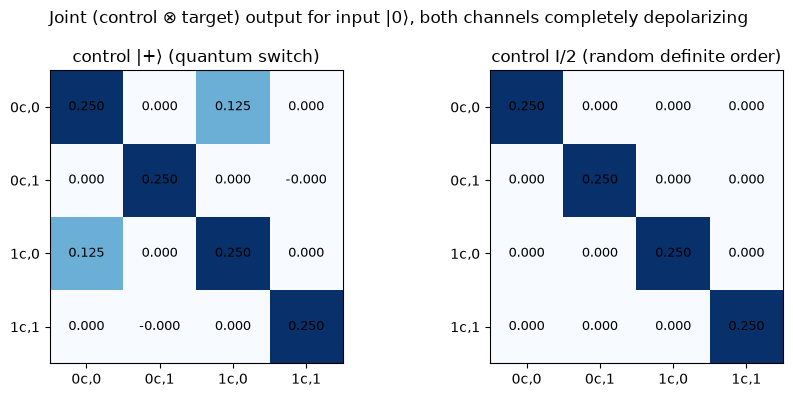

In [7]:
out_q = s.quantum_switch(s.dm(s.KET0), dep, dep)
out_c = s.quantum_switch(s.dm(s.KET0), dep, dep, control=np.eye(2) / 2)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, M, title in [(ax[0], out_q, "control |+⟩ (quantum switch)"), (ax[1], out_c, "control I/2 (random definite order)")]:
    im = a.imshow(np.real(M), vmin=0, vmax=0.25, cmap="Blues")
    for i in range(4):
        for j in range(4):
            a.text(j, i, f"{np.real(M[i, j]):.3f}", ha="center", va="center", fontsize=9)
    lab = ["0c,0", "0c,1", "1c,0", "1c,1"]
    a.set_xticks(range(4), lab); a.set_yticks(range(4), lab); a.set_title(title)
plt.suptitle("Joint (control ⊗ target) output for input |0⟩, both channels completely depolarizing")
plt.tight_layout(); plt.show()
assert abs(np.real(out_q[0, 2]) - 1 / 8) < 1e-12 and abs(out_c[0, 2]) < 1e-12

## Going deeper: the switch is a supermap, not a Kraus trick

Kraus operators are not unique. $\{A_i\}$ and $\{A'_k=\sum_i u_{ki}A_i\}$ with $u$ unitary describe the same channel. A legitimate higher-order transformation must not depend on that choice. Insert $A'_k$ and $B'_l$ into $W_{kl}$ and sum. The cross terms cancel because $u$ is unitary, so the switch output depends only on the channels. The next cell checks this numerically with random unitary mixings, including mixings of the amplitude-damping channel.

In [8]:
def random_unitary(n, rng):
    Q, R = np.linalg.qr(rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n)))
    return Q * (np.diag(R) / np.abs(np.diag(R)))

def remix(K, u):
    return [sum(u[k, i] * K[i] for i in range(len(K))) for k in range(len(K))]

g2 = np.random.default_rng(5)
for KA, KB in [(dep, dep), (s.amplitude_damping_kraus(0.3), s.dephasing_kraus(0.6))]:
    for _ in range(10):
        rho = random_qubit_state()
        KA2, KB2 = remix(KA, random_unitary(len(KA), g2)), remix(KB, random_unitary(len(KB), g2))
        assert s.is_cptp(KA2) and s.is_cptp(KB2)
        assert np.allclose(s.quantum_switch(rho, KA, KB), s.quantum_switch(rho, KA2, KB2), atol=1e-12)
print("switch output is independent of the Kraus decomposition (20 random checks)")

switch output is independent of the Kraus decomposition (20 random checks)

## Exercises

:::{admonition} Exercise: :label: lab09-ex1
:class: tip
For two completely depolarizing qubit channels in the switch with control $|+\rangle$, what is the probability of control outcome $+$?
:::

:::{dropdown} Solution
$P(+)=\tfrac12\big(1+\langle X_c\rangle\big)=\tfrac12\big(1+\tfrac14\big)=5/8$.
:::

:::{admonition} Exercise: :label: lab09-ex2
:class: tip
Set the control to $|0\rangle$ instead of $|+\rangle$. What is the joint output, and is any information about $\rho$ left?
:::

:::{dropdown} Solution
Only the first term of $W_{ij}$ acts, so the output is $|0\rangle\langle0|_c\otimes(\mathcal B\circ\mathcal A)(\rho)=|0\rangle\langle0|\otimes I/2$. No information about $\rho$ remains. This is just a definite order.
:::

:::{admonition} Exercise: :label: lab09-ex3
:class: tip
Show that the post-selected map $\rho\mapsto(2I+\rho)/5$ is itself a depolarizing channel, and find its strength.
:::

:::{dropdown} Solution
$(2I+\rho)/5=\tfrac15\rho+\tfrac45\cdot\tfrac I2$, which is depolarizing with $p=4/5$. The Bloch vector shrinks by $1-p=1/5$.
:::

## Check yourself

In [9]:
out = s.quantum_switch(random_qubit_state(), dep, dep)
assert abs(condition_on(out, PLUS)[0] - 0.5 * (1 + np.real(np.trace(out @ s.kron(s.X, s.I2))))) < 1e-12
assert abs(condition_on(out, PLUS)[0] - 5 / 8) < 1e-12
for rho in inputs[:5]:
    assert np.allclose(s.quantum_switch(rho, dep, dep, control=s.dm(s.KET0)), np.kron(s.dm(s.KET0), np.eye(2) / 2))
    assert np.allclose((2 * np.eye(2) + rho) / 5, s.apply_kraus(rho, s.depolarizing_kraus(0.8)))
print("All checks passed.")

All checks passed.


## Limits of this model

The control is ideal. The control qubit is noiseless and perfectly coherent. Real implementations have imperfect interferometers.

Implementation questions remain open here. Photonic experiments realize the switch with spatial or polarization modes. Does a given experiment realize "indefinite causal order", or a time-delocalized definite-order process? That is a matter of interpretation, and this code does not address it.

The comparison class matters. We compared against definite orders that *lack* a coherent control. Can definite-order schemes that *also* use coherent control reproduce such effects? That question is part of the debate mentioned above. We did not simulate such schemes, and the right baseline depends on the question.

The channels are toys. We considered only depolarizing channels on one qubit (and, in one check, amplitude-damping and dephasing channels).